![Banner](../images/09_13_banner_rs_soil_moisture.png)

# ESA CCI vs ERA5-Land

Satellites observe soil moisture; land surface models compute it from rain, radiation and soil
physics. ERA5-Land, ECMWF's land reanalysis at 0.1 degree, is the most used model reference: hourly,
gap free, four soil layers, from 1950. Comparing a merged satellite record with a reanalysis tells us
where each can be trusted, because their errors come from different sources. This notebook compares
ESA CCI COMBINED with ERA5-Land layer 1 (0 to 7 cm) over Iowa from 2015 to 2024 and over Bangladesh
from 2010 to 2024: seasonal cycles, biases, raw and anomaly correlations per cell, and agreement with
an in situ station.

## Overview

### ERA5-Land

ERA5-Land reruns the land component (HTESSEL) of the ERA5 reanalysis at 0.1 degree, forced by ERA5
near-surface weather with lapse-rate corrections (Munoz-Sabater et al. 2021). It does not assimilate
soil moisture observations itself (ERA5 does assimilate ASCAT and screen-level data in its own land
analysis). Its soil water layers are 0 to 7, 7 to 28, 28 to 100 and 100 to 289 cm (`swvl1` to `swvl4`),
in m3 m-3 with the model's own soil texture classes.

### What a comparison can show

| Metric | Measures | Sensitive to |
|---|---|---|
| bias | difference in level | soil parameters of the model, retrieval calibration |
| raw correlation | shared seasonal cycle and events | dominated by the seasonal cycle |
| anomaly correlation | shared short-term events | rain timing in the model, retrieval noise |
| ubRMSD | spread of differences after removing the bias | both |

Levels rarely agree: the model's porosity and wilting point are not the real soil's, and the
satellite sees a thinner layer than 7 cm. Anomaly correlations are the fairest test of whether two
records carry the same information.

### Where each is better

Satellite records are best where vegetation is sparse and rain gauges are few (the model's forcing
is poor); models are best under dense vegetation, in frozen periods and where gauges are dense. The
comparison maps show this division of labour.

## Reanalysis Comparison with GeoLattice

| Function | Purpose |
|---|---|
| `sm.read_era5_land` (through `sd.era5_land`) | ERA5-Land daily means from the Open-Meteo archive |
| `sd.cci` | ESA CCI COMBINED cubes |
| `sm.temporal_match`, `sm.validation_metrics` | matching and metrics, raw and anomaly |
| `sm.sm_anomaly` | anomalies from a day-of-year climatology |

### Learning objectives

1. Read ERA5-Land soil water at grid points without an account.
2. Compare the seasonal cycles and levels of a satellite record and a reanalysis.
3. Map raw and anomaly correlations per cell and interpret their difference.
4. Judge both against an in situ station.

### Data

| Dataset | Content |
|---|---|
| ESA CCI SM v09.2 COMBINED | 0.25 degree daily soil moisture, Iowa region 2015 to 2024, Bangladesh 2010 to 2024 |
| ERA5-Land (Open-Meteo archive) | daily mean layer 1 (0 to 7 cm) at 0.5 degree points over Iowa and 1 degree points over Bangladesh; three layers at the stations |
| USCRN Des Moines 17 E | in situ 5 cm |

### Contents

- Setup
- Matching the two grids
- Seasonal cycles and levels
- Raw and anomaly correlation per cell
- Bangladesh
- Against an in situ station
- Summary and exercises

## Setup

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.soil_moisture as sm  # soil moisture physics, products, retrieval and validation
import sm_data as sd  # chapter helper: subsets, downloads and caches the data

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs")  # results written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
print("GeoLattice", geolattice.__version__, "| data folder", sd.DATA.relative_to(sd.DATA.parents[3]))  # versions and paths

cci = sm.mask_quality(sd.cci("COMBINED"), level="all").sm  # CCI over Iowa, frozen and water removed
era = sd.era5_land().swvl1.sel(time=slice("2015", "2024"))  # ERA5-Land 0 to 7 cm at 0.5 degree points
print("CCI", dict(cci.sizes), "| ERA5-Land", dict(era.sizes))  # dimensions


def pair_on_points(sat, model):  # satellite value of the cell under each model point
    s = sat.sel(lat=model.lat, lon=model.lon, method="nearest").assign_coords(lat=model.lat, lon=model.lon)  # nearest 0.25 degree cell
    return xr.align(s, model, join="inner")  # same days


def cell_metrics(sat, model):  # per-cell bias, correlations and ubRMSD
    s, m = pair_on_points(sat, model)  # aligned
    ok = s.notnull() & m.notnull()  # paired days
    s, m = s.where(ok), m.where(ok)  # same sample
    sa, ma = sm.sm_anomaly(s, window=31), sm.sm_anomaly(m, window=31)  # anomalies
    d = s - m  # differences
    return xr.Dataset({"bias": d.mean("time"), "r": xr.corr(s, m, "time"), "anomaly_r": xr.corr(sa, ma, "time"),
                       "ubrmsd": np.sqrt((d ** 2).mean("time") - d.mean("time") ** 2), "n": ok.sum("time")})  # metrics

GeoLattice 0.3.49 | data folder GeoLattice/Data/08_remote_sensing/08_13_soil_moisture


CCI {'time': 3653, 'lat': 18, 'lon': 30} | ERA5-Land {'time': 3653, 'lat': 9, 'lon': 15}


## Matching the two grids

ERA5-Land is read at 0.5 degree points (to stay within Open-Meteo's free daily quota); each point
takes the CCI cell that contains it.

In [2]:
s, m = pair_on_points(cci, era)  # paired cubes
print(f"{m.sizes['lat'] * m.sizes['lon']} points, {int((s.notnull() & m.notnull()).sum())} paired cell-days")  # sample

135 points, 297576 paired cell-days


## Seasonal cycles and levels

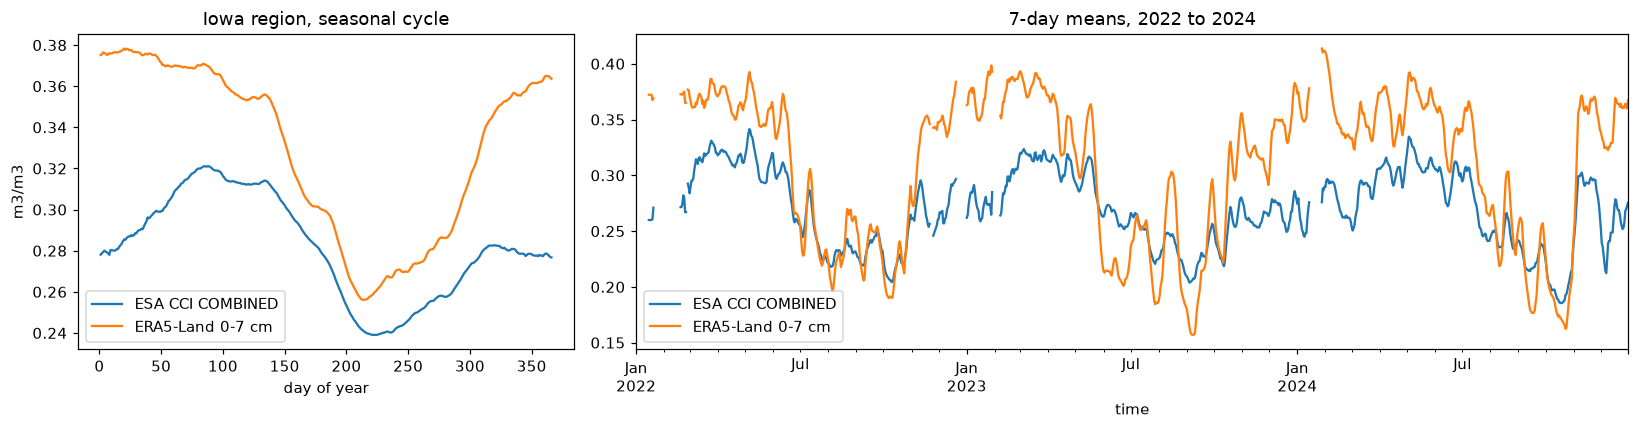

mean difference CCI minus ERA5-Land -0.042 m3/m3


In [3]:
reg = pd.DataFrame({"ESA CCI COMBINED": s.where(m.notnull()).mean(("lat", "lon")).to_series(),
                    "ERA5-Land 0-7 cm": m.where(s.notnull()).mean(("lat", "lon")).to_series()})  # regional means on shared days
clim = reg.groupby(reg.index.dayofyear).mean().rolling(31, center=True, min_periods=5).mean()  # smoothed seasonal cycle
fig, ax = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [1, 2]})  # cycle and series
clim.plot(ax=ax[0]); ax[0].set_xlabel("day of year"); ax[0].set_ylabel("m3/m3"); ax[0].set_title("Iowa region, seasonal cycle")  # cycle
reg.loc["2022":"2024"].rolling(7, min_periods=3).mean().plot(ax=ax[1]); ax[1].set_title("7-day means, 2022 to 2024")  # series
plt.tight_layout(); plt.show()  # draw
print(f"mean difference CCI minus ERA5-Land {float((reg.iloc[:, 0] - reg.iloc[:, 1]).mean()):+.3f} m3/m3")  # level

## Raw and anomaly correlation per cell

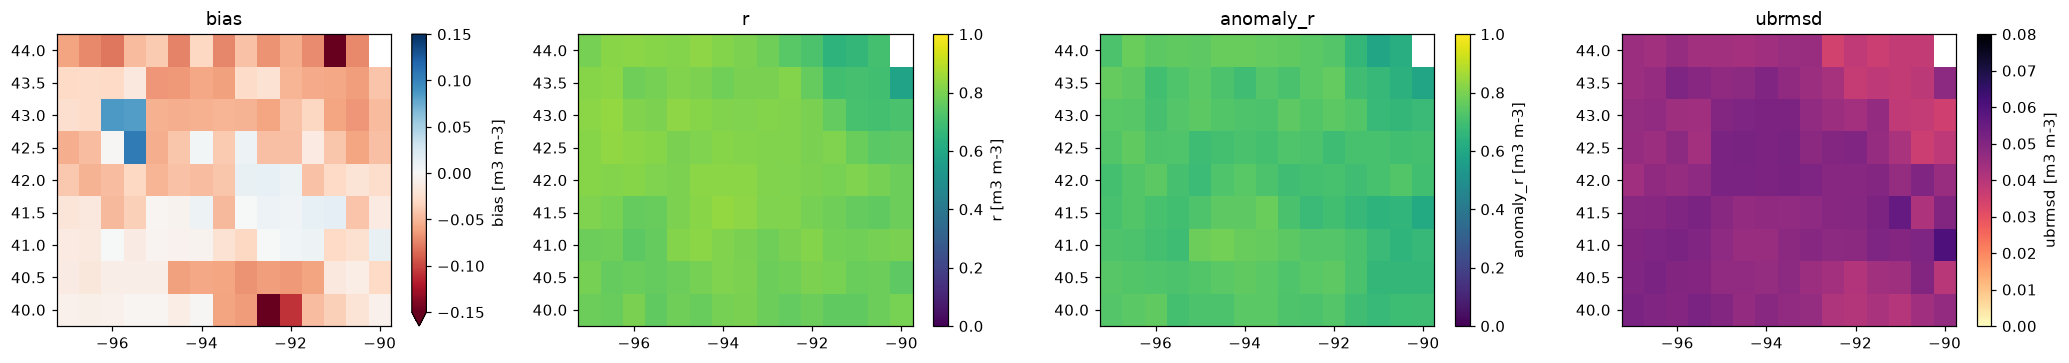

,bias,r,anomaly_r,ubrmsd
"Iowa, median of cells",-0.034,0.797,0.719,0.047


In [4]:
met = cell_metrics(cci, era)  # per-cell metrics
fig, ax = plt.subplots(1, 4, figsize=(19, 3.4))  # four maps
for a, (v, cmap, lim) in zip(ax, (("bias", "RdBu", (-0.15, 0.15)), ("r", "viridis", (0, 1)), ("anomaly_r", "viridis", (0, 1)), ("ubrmsd", "magma_r", (0, 0.08)))):  # metrics
    met[v].plot(ax=a, cmap=cmap, vmin=lim[0], vmax=lim[1]); a.set_title(v); a.set_xlabel(""); a.set_ylabel("")  # map
plt.tight_layout(); plt.show()  # draw
display(met[["bias", "r", "anomaly_r", "ubrmsd"]].median().to_pandas().rename("Iowa, median of cells").to_frame().T.round(3))  # summary

The level differs by several hundredths of m3 m-3, a difference of definitions more than of skill.
Raw correlations are high because both follow the same seasonal cycle; anomaly correlations are lower
and are the real test of shared information on events. Over Iowa, with dense rain gauges and a good
model forcing, the reanalysis is a strong reference.

## Bangladesh

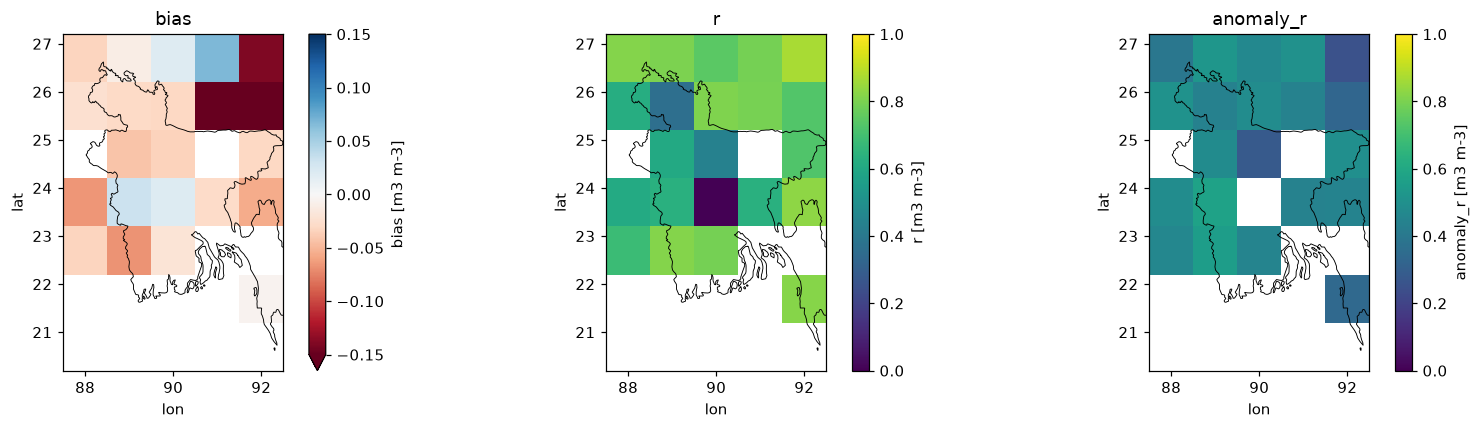

,bias,r,anomaly_r,ubrmsd
Iowa,-0.034,0.797,0.719,0.047
Bangladesh,-0.031,0.736,0.462,0.074


In [5]:
cci_b = sm.mask_quality(sd.cci("COMBINED", sd.BANGLADESH, ("1979-01-01", "2024-12-31"), "bangladesh"), level="all").sm.sel(time=slice("2010", "2024"))  # CCI
era_b = sd.era5_land(sd.BANGLADESH, ("2010-01-01", "2024-12-31"), "bangladesh", 1.0).swvl1  # ERA5-Land at 1 degree points
met_b = cell_metrics(cci_b, era_b)  # per-cell metrics
bgd = sd.boundaries("BGD", "ADM0")  # outline
fig, ax = plt.subplots(1, 3, figsize=(15, 4))  # three maps
for a, (v, cmap, lim) in zip(ax, (("bias", "RdBu", (-0.15, 0.15)), ("r", "viridis", (0, 1)), ("anomaly_r", "viridis", (0, 1)))):  # metrics
    met_b[v].plot(ax=a, cmap=cmap, vmin=lim[0], vmax=lim[1]); bgd.boundary.plot(ax=a, color="k", lw=0.6); a.set_title(v)  # map
plt.tight_layout(); plt.show()  # draw
both = pd.DataFrame({"Iowa": met[["bias", "r", "anomaly_r", "ubrmsd"]].median().to_pandas(),
                     "Bangladesh": met_b[["bias", "r", "anomaly_r", "ubrmsd"]].median().to_pandas()}).T  # comparison
display(both.round(3))  # table

Over Bangladesh the anomaly agreement is weaker: monsoon flooding, rice paddies and dense
vegetation degrade the satellite retrievals, and the reanalysis forcing is less constrained by rain
gauges. Disagreement does not tell which is wrong; triple collocation (notebook 23) adds a third,
independent product to separate their errors.

## Against an in situ station

In [6]:
st = sd.STATIONS.loc["USCRN Des Moines 17 E"]  # station
ins = sd.uscrn().sm_5.resample("1D").mean().loc["2015":"2024"]  # daily 5 cm
pts = sd.era5_land_points().sel(point="USCRN Des Moines 17 E")  # ERA5-Land at the station point (0.1 degree native)
cci_pt = cci.sel(lat=st.lat, lon=st.lon, method="nearest").to_series()  # CCI cell of the station
warm = lambda x: x[(x.index.month >= 4) & (x.index.month <= 10)]  # unfrozen months
tab = pd.DataFrame({"ESA CCI COMBINED": sm.validation_metrics(warm(ins), warm(cci_pt), anomalies=True),
                    "ERA5-Land layer 1": sm.validation_metrics(warm(ins), warm(pts.swvl1.to_series()), anomalies=True)}).T  # metrics
display(tab[["n", "bias", "ubrmse", "pearson_r", "anomaly_r"]].astype(float).round(3))  # table

,n,bias,ubrmse,pearson_r,anomaly_r
ESA CCI COMBINED,1641.0,-0.024,0.049,0.714,0.706
ERA5-Land layer 1,1851.0,0.022,0.052,0.736,0.694


At the station both records capture the events, and the reanalysis, with a value every day and
forcing from a dense gauge network, matches the station at least as well as the satellite record.
Its bias is a matter of soil parameters, which is why satellite and model records are usually
compared after rescaling.

## Summary and exercises

- ERA5-Land is a gap-free model reference whose levels depend on its own soil parameters.
- Raw correlations with CCI are high because of the shared seasonal cycle; anomaly correlations are
  the meaningful test and are lower.
- Agreement is better over Iowa than over Bangladesh, where flooding, vegetation and sparse gauges
  degrade both records.
- At the Iowa station the reanalysis and the satellite record perform similarly after bias removal.

**Exercises**

1. Compare CCI with ERA5-Land layer 2 (7 to 28 cm) at the station. Does the anomaly correlation rise or
   fall, and why?
2. Rescale CCI to ERA5-Land per cell with `sm.rescale(..., method="cdf")` and map the remaining ubRMSD.
3. Split the Bangladesh comparison into the Rabi and monsoon seasons. Where does the agreement break
   down?